# Module 2 · Notebook 2: The transformer block

Notebook 1 built attention. A transformer **block** wraps it with three more pieces, and the model needs one more thing to know word order:

| Step | What we do | Proof |
|---|---|---|
| 1 | **LayerNorm**: keep every token's vector at a fixed scale | mean 0 / variance 1, and the gradient matches the textbook closed form |
| 2 | **MLP**: a small per-token network (with GELU) | gradient check |
| 3 | **Residual connections**: why every layer is `x + f(x)` | gradient size through a 30-layer stack, with and without |
| 4 | **The full block**, GPT-2 style | gradient check of all parameters + the no-future-leak test |
| 5 | **Why position information is needed at all** | shuffle the tokens, and attention cannot tell |
| 6 | **Three positional encodings**: sinusoidal, learned, RoPE | RoPE: the score depends only on the distance between tokens |

Like notebook 1, everything is built from the existing ops of the Module 1 engine.

In [1]:
import sys, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

LAB = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(LAB / "01-autograd"))
from autograd import Tensor, softmax
from gradcheck import gradcheck, TOL

print("python", sys.version.split()[0], "| numpy", np.__version__)
rng = np.random.default_rng(0)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

python 3.12.15 | numpy 2.5.3


**Attention from notebook 1**, repeated here so this notebook runs on its own:

In [2]:
def swap_last2(t):
    n = t.data.ndim
    return t.transpose(tuple(range(n - 2)) + (n - 1, n - 2))

def causal_mask(T):
    return np.triu(np.full((T, T), -np.inf), k=1)

def attention(q, k, v, causal=True):
    T, d = q.shape[-2], q.shape[-1]
    scores = (q @ swap_last2(k)) * (1.0 / np.sqrt(d))
    if causal:
        scores = scores + causal_mask(T)
    return softmax(scores, axis=-1) @ v

def split_heads(x, H):
    B, T, C = x.shape
    return x.reshape(B, T, H, C // H).transpose((0, 2, 1, 3))

def merge_heads(x):
    B, H, T, hs = x.shape
    return x.transpose((0, 2, 1, 3)).reshape(B, T, H * hs)

def multi_head_attention(x, Wq, Wk, Wv, Wo, H, causal=True):
    q, k, v = split_heads(x @ Wq, H), split_heads(x @ Wk, H), split_heads(x @ Wv, H)
    return merge_heads(attention(q, k, v, causal)) @ Wo

## Step 1: LayerNorm

As vectors pass through many layers, their scale drifts: some tokens' vectors grow, others shrink, and every layer has to cope with a moving target. **LayerNorm** resets each token's vector to a fixed scale, independently for every token:

$$\hat{x} = \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}}, \qquad \text{LayerNorm}(x) = \gamma \odot \hat{x} + \beta$$

- $\mu$, $\sigma^2$: the mean and variance over the $C$ numbers of **one token** (not over the batch; that would be BatchNorm).
- $\epsilon = 10^{-5}$: stops a division by zero when a vector is constant.
- $\gamma$, $\beta$: learned per-dimension scale and shift, so the model can undo the normalization where it helps.

The square root needs no new op: $(\sigma^2 + \epsilon)^{-1/2}$ is just `** -0.5`.

In [3]:
def layer_norm(x, gamma, beta, eps=1e-5):
    mu = x.mean(axis=-1, keepdims=True)
    xc = x - mu
    var = (xc ** 2).mean(axis=-1, keepdims=True)
    return xc * (var + eps) ** -0.5 * gamma + beta

B, T, C = 2, 5, 8
x_np = rng.standard_normal((B, T, C)) * 3 + 2            # deliberately off-center and wide
out = layer_norm(Tensor(x_np), Tensor(np.ones(C)), Tensor(np.zeros(C))).data

print("input : per-token mean ranges", np.round([x_np.mean(-1).min(), x_np.mean(-1).max()], 2),
      "| per-token std ranges", np.round([x_np.std(-1).min(), x_np.std(-1).max()], 2))
print("output: max |mean| =", f"{np.abs(out.mean(-1)).max():.1e}",
      "| var ranges", np.round([out.var(-1).min(), out.var(-1).max()], 6))

input : per-token mean ranges [-0.65  4.16] | per-token std ranges [1.67 3.43]
output: max |mean| = 1.9e-16 | var ranges [0.999996 0.999999]


**Proof 1: gradient check** on $x$, $\gamma$ and $\beta$.

**Proof 2: the closed form.** LayerNorm's backward pass has a well-known formula. With $g = \partial L/\partial \hat{x}$ (the incoming gradient times $\gamma$), $N = C$ and $r = 1/\sqrt{\sigma^2 + \epsilon}$:

$$\frac{\partial L}{\partial x} = \frac{r}{N}\Big(N g - \textstyle\sum g - \hat{x} \sum (g \odot \hat{x})\Big)$$

The engine never sees this formula: it only knows mean, subtract, square, power and multiply. It should still land on exactly this result.

In [4]:
gamma_np, beta_np = rng.standard_normal(C), rng.standard_normal(C)
err = gradcheck(lambda t: layer_norm(t[0], t[1], t[2]), [x_np, gamma_np, beta_np])
print(f"LayerNorm gradcheck: rel_err = {err:.1e}   {'OK' if err < TOL else 'FAIL'}")

# closed form vs autograd, for L = sum(R * LayerNorm(x))
R = rng.standard_normal((B, T, C))
x = Tensor(x_np)
(layer_norm(x, Tensor(gamma_np), Tensor(beta_np)) * R).sum().backward()

mu = x_np.mean(-1, keepdims=True)
r = 1 / np.sqrt(x_np.var(-1, keepdims=True) + 1e-5)
xhat = (x_np - mu) * r
g = R * gamma_np
closed = r / C * (C * g - g.sum(-1, keepdims=True) - xhat * (g * xhat).sum(-1, keepdims=True))
print(f"max |autograd - closed form| = {np.abs(x.grad - closed).max():.1e}")

LayerNorm gradcheck: rel_err = 3.1e-09   OK
max |autograd - closed form| = 4.4e-16


## Step 2: The MLP

Attention **mixes information between tokens**. The MLP then **processes each token on its own**: the same small two-layer network is applied to every position independently.

$$\text{MLP}(x) = \text{GELU}(x W_1 + b_1)\, W_2 + b_2, \qquad W_1: C \times 4C, \quad W_2: 4C \times C$$

The hidden layer is 4× wider than $C$ (GPT-2's choice). **GELU** is a smooth version of ReLU; GPT-2 uses this tanh approximation, which is built from ops we already have:

$$\text{GELU}(x) \approx 0.5\, x \left(1 + \tanh\!\left(\sqrt{2/\pi}\,(x + 0.044715\, x^3)\right)\right)$$

In [5]:
def gelu(x):
    return 0.5 * x * (1 + (math.sqrt(2 / math.pi) * (x + 0.044715 * x ** 3)).tanh())

def mlp(x, W1, b1, W2, b2):
    return gelu(x @ W1 + b1) @ W2 + b2

# how close is the approximation to the exact GELU, x * Phi(x)?
z = np.linspace(-6, 6, 2001)
exact = z * 0.5 * (1 + np.vectorize(math.erf)(z / math.sqrt(2)))
print(f"tanh-GELU vs exact GELU on [-6, 6]: max difference = {np.abs(gelu(Tensor(z)).data - exact).max():.1e}")

err = gradcheck(lambda t: gelu(t[0]), [rng.standard_normal((4, 6))])
print(f"GELU gradcheck: rel_err = {err:.1e}   {'OK' if err < TOL else 'FAIL'}")

inputs = [rng.standard_normal((2, 3, C)), rng.standard_normal((C, 4 * C)) * 0.3, np.zeros(4 * C),
          rng.standard_normal((4 * C, C)) * 0.3, np.zeros(C)]
err = gradcheck(lambda t: mlp(*t), inputs)
print(f"MLP gradcheck: rel_err = {err:.1e}   {'OK' if err < TOL else 'FAIL'}")

tanh-GELU vs exact GELU on [-6, 6]: max difference = 4.7e-04
GELU gradcheck: rel_err = 4.0e-11   OK
MLP gradcheck: rel_err = 4.9e-10   OK


## Step 3: Residual connections

Every sub-layer in a transformer is wrapped as $x + f(x)$ instead of just $f(x)$. The reason shows up in the backward pass:

$$\frac{\partial\, (x + f(x))}{\partial x} = I + \frac{\partial f}{\partial x}$$

The $I$ (identity) is a **gradient highway**: even if a layer's own derivative is tiny, the gradient still passes straight through. Without it, the gradient reaching the first layer is a **product** of every layer's derivative, and a product of many numbers below 1 vanishes.

The measurement: a stack of identical layers $f(x) = \tanh(xW)$ with small random weights, and the size of the gradient at the input, as the stack gets deeper.

In [6]:
C_r, depth_max = 16, 30
Ws = [rng.standard_normal((C_r, C_r)) * (0.5 / np.sqrt(C_r)) for _ in range(depth_max)]
x0_np = rng.standard_normal((4, C_r))
R_out = rng.standard_normal((4, C_r))

def input_grad_norm(depth, residual):
    x0 = Tensor(x0_np)
    h = x0
    for W in Ws[:depth]:
        f = (h @ Tensor(W)).tanh()
        h = h + f if residual else f
    (h * R_out).sum().backward()
    return np.linalg.norm(x0.grad)

print(f"{'depth':>5s} | {'plain: |dL/dx0|':>16s} | {'residual: |dL/dx0|':>19s}")
depths = [1, 2, 5, 10, 20, 30]
for D in depths:
    print(f"{D:5d} | {input_grad_norm(D, False):16.2e} | {input_grad_norm(D, True):19.2e}")

depth |  plain: |dL/dx0| |  residual: |dL/dx0|
    1 |         3.62e+00 |            8.04e+00
    2 |         1.48e+00 |            8.27e+00
    5 |         1.66e-01 |            9.71e+00
   10 |         5.24e-03 |            1.58e+01
   20 |         2.44e-06 |            1.97e+01
   30 |         2.59e-09 |            2.12e+01


In the plain stack the gradient shrinks by roughly the same factor at every layer: after 30 layers it is about a billion times smaller, and there is almost nothing left to learn from. With residuals it stays large at every depth (it even grows a little, because each layer adds its own path on top of the identity). This is the main reason transformers can be stacked dozens of layers deep.

## Step 4: The full block

GPT-2 puts the LayerNorm **before** each sub-layer ("pre-LN"), inside the residual branch:

$$x \leftarrow x + \text{MultiHeadAttention}(\text{LN}_1(x)), \qquad x \leftarrow x + \text{MLP}(\text{LN}_2(x))$$

Keeping the residual path itself free of any LayerNorm means the identity highway from Step 3 runs uninterrupted from the top of the network to the bottom.

In [7]:
def init_block(C, H, rng):
    s = 1 / np.sqrt(C)
    return {
        "ln1_g": np.ones(C), "ln1_b": np.zeros(C),
        "Wq": rng.standard_normal((C, C)) * s, "Wk": rng.standard_normal((C, C)) * s,
        "Wv": rng.standard_normal((C, C)) * s, "Wo": rng.standard_normal((C, C)) * s,
        "ln2_g": np.ones(C), "ln2_b": np.zeros(C),
        "W1": rng.standard_normal((C, 4 * C)) * s, "b1": np.zeros(4 * C),
        "W2": rng.standard_normal((4 * C, C)) * (1 / np.sqrt(4 * C)), "b2": np.zeros(C),
    }

def block(x, p, H):
    x = x + multi_head_attention(layer_norm(x, p["ln1_g"], p["ln1_b"]), p["Wq"], p["Wk"], p["Wv"], p["Wo"], H)
    x = x + mlp(layer_norm(x, p["ln2_g"], p["ln2_b"]), p["W1"], p["b1"], p["W2"], p["b2"])
    return x

C, H = 8, 2
params = init_block(C, H, rng)
for k in ["ln1_g", "ln1_b", "ln2_g", "ln2_b"]:          # perturb so the check isn't on a special point
    params[k] = params[k] + rng.standard_normal(C) * 0.1
names = list(params)
x_np = rng.standard_normal((1, 4, C))

def block_from_list(t):
    return block(t[0], dict(zip(names, t[1:])), H)

inputs = [x_np] + [params[k] for k in names]
err = gradcheck(block_from_list, inputs)
print(f"full block: {sum(a.size for a in inputs)} numbers checked (x + {len(names)} parameter arrays)")
print(f"gradcheck: rel_err = {err:.1e}   {'OK' if err < TOL else 'FAIL'}")

full block: 872 numbers checked (x + 12 parameter arrays)
gradcheck: rel_err = 8.3e-10   OK


**The no-future-leak test, on the whole block.** LayerNorm and the MLP work on each token separately, and attention is masked, so the block as a whole must still never let a later token affect an earlier output.

In [8]:
T = 6
x_np = rng.standard_normal((1, T, C))
x2 = x_np.copy()
x2[0, 3] += rng.standard_normal(C)
P = {k: Tensor(v) for k, v in params.items()}
diff = np.abs(block(Tensor(x_np), P, H).data - block(Tensor(x2), P, H).data).max(axis=-1)[0]
for pos in range(T):
    print(f"position {pos}: max change = {diff[pos]:.2e}   ({'before' if pos < 3 else 'at/after'} the change)")

position 0: max change = 0.00e+00   (before the change)
position 1: max change = 0.00e+00   (before the change)
position 2: max change = 0.00e+00   (before the change)
position 3: max change = 1.69e+00   (at/after the change)
position 4: max change = 2.22e-01   (at/after the change)
position 5: max change = 1.67e-01   (at/after the change)


## Step 5: Why the model needs position information

Look at attention without the mask: scores are dot products between tokens, and the output is a weighted sum. Nothing in that computation knows **where** a token is. If you shuffle the input tokens, the outputs come out shuffled in exactly the same way, and are otherwise identical.

So "dog bites man" and "man bites dog" look the same to attention, apart from their order in the list. (The causal mask breaks the symmetry a little: each token sees a different number of predecessors, and a model can partly infer position from that. But it gives no explicit position signal.)

In [9]:
T, C = 5, 8
x_np = rng.standard_normal((1, T, C))
Wqkvo = [Tensor(rng.standard_normal((C, C)) / np.sqrt(C)) for _ in range(4)]
perm = rng.permutation(T)

out = multi_head_attention(Tensor(x_np), *Wqkvo, H=2, causal=False).data
out_shuffled_input = multi_head_attention(Tensor(x_np[:, perm]), *Wqkvo, H=2, causal=False).data

print("permutation:", perm)
print("max |attn(shuffled x) - shuffled attn(x)| =", f"{np.abs(out_shuffled_input - out[:, perm]).max():.1e}")

permutation: [0 2 1 4 3]
max |attn(shuffled x) - shuffled attn(x)| = 2.2e-16


Equal to rounding error: attention alone is blind to order. Positional encodings fix that, in one of three ways.

## Step 6: Three positional encodings

### 6a. Sinusoidal (the original transformer)

Add a fixed pattern to each token's vector before the first block. Dimension pair $i$ is a sine/cosine wave over positions, each pair at a different frequency:

$$PE_{(pos,\, 2i)} = \sin\!\left(\frac{pos}{10000^{2i/C}}\right), \qquad PE_{(pos,\, 2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/C}}\right)$$

Low dimensions change fast (they distinguish neighbors), high dimensions change slowly (they distinguish far-apart positions). It is like a clock with many hands. Nothing is learned, and it can be computed for any position.

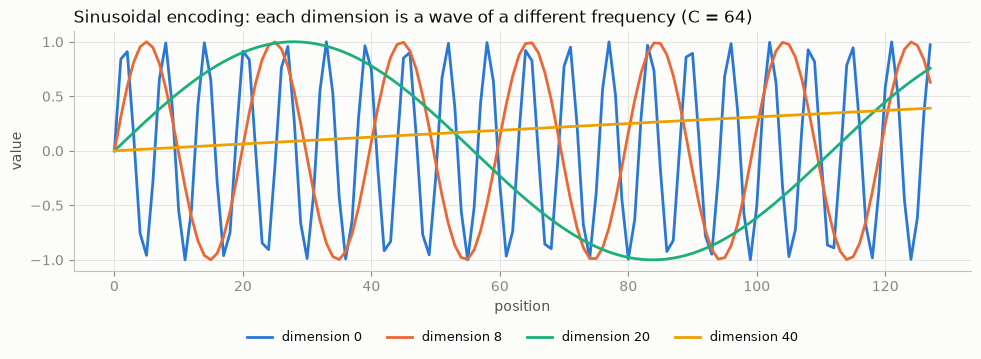

with sinusoidal PE, max |attn(shuffled) - shuffled attn| = 0.45  <- order now matters


In [10]:
def sinusoidal(T, C):
    pos = np.arange(T)[:, None]
    freq = 1.0 / 10000 ** (np.arange(0, C, 2) / C)
    pe = np.zeros((T, C))
    pe[:, 0::2] = np.sin(pos * freq)
    pe[:, 1::2] = np.cos(pos * freq)
    return pe

pe = sinusoidal(128, 64)
fig, ax = plt.subplots(figsize=(10, 3.8))
for color, dim in zip(SERIES, [0, 8, 20, 40]):
    ax.plot(pe[:, dim], color=color, label=f"dimension {dim}")
ax.set_xlabel("position"); ax.set_ylabel("value")
ax.set_title("Sinusoidal encoding: each dimension is a wave of a different frequency (C = 64)", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=9)
plt.tight_layout()
plt.show()

out_pe = multi_head_attention(Tensor(x_np + sinusoidal(T, C)), *Wqkvo, H=2, causal=False).data
out_pe_shuf = multi_head_attention(Tensor(x_np[:, perm] + sinusoidal(T, C)), *Wqkvo, H=2, causal=False).data
print("with sinusoidal PE, max |attn(shuffled) - shuffled attn| =", f"{np.abs(out_pe_shuf - out_pe[:, perm]).max():.2f}",
      " <- order now matters")

### 6b. Learned (GPT-2)

Even simpler: a parameter table of shape `(T_max, C)`, one learned vector per position, added to the token vectors. The model learns whatever position pattern is useful.

The catch: it only has rows for positions $0 \dots T_{max}-1$. A position it never trained on has **no vector at all**. (Looking up rows by position is an embedding lookup, the one new engine op this lab will need, in Module 3. Within this notebook a full `(T, C)` parameter added to `x` behaves identically.)

### 6c. RoPE (LLaMA, Mistral, Qwen, most modern models)

Instead of **adding** something to the token vectors, RoPE **rotates** the query and key vectors inside attention, by an angle proportional to the position. Each pair of dimensions $(x_{2i}, x_{2i+1})$ is rotated by $pos \cdot \theta_i$:

$$\begin{pmatrix} x_{2i}' \\ x_{2i+1}' \end{pmatrix} = \begin{pmatrix} \cos(pos\,\theta_i) & -\sin(pos\,\theta_i) \\ \sin(pos\,\theta_i) & \cos(pos\,\theta_i) \end{pmatrix} \begin{pmatrix} x_{2i} \\ x_{2i+1} \end{pmatrix}, \qquad \theta_i = 10000^{-2i/d}$$

**Why rotate?** The dot product of two rotated vectors depends only on the **difference** of their angles. So the score between a query at position $m$ and a key at position $n$ depends only on $m - n$: attention sees **relative** distance, not absolute position.

In code: $x' = x \odot \cos + \text{swap}(x) \odot \sin$, where $\text{swap}$ maps each pair $(x_0, x_1) \to (-x_1, x_0)$. That swap is a fixed matrix, so it is just one matmul: no new op.

One detail: this pairs **neighbouring** dimensions $(0,1), (2,3), \dots$, as in the original RoFormer paper and GPT-J. LLaMA's code instead pairs dimension $i$ with $i + d/2$ (`rotate_half`). It is the same rotation with the dimensions laid out differently, so either works when training from scratch, but the two can't be mixed when loading real model weights.

In [11]:
def rope_tables(T, d, base=10000):
    assert d % 2 == 0, "rope needs an even head size"
    theta = base ** (-np.arange(0, d, 2) / d)          # one frequency per pair
    ang = np.arange(T)[:, None] * theta[None, :]        # (T, d/2)
    return np.repeat(np.cos(ang), 2, axis=1), np.repeat(np.sin(ang), 2, axis=1)   # (T, d) each

def pair_swap_matrix(d):
    # x @ S maps every pair (x0, x1) -> (-x1, x0)
    S = np.zeros((d, d))
    for i in range(0, d, 2):
        S[i + 1, i] = -1
        S[i, i + 1] = 1
    return S

def rope(x, cos, sin, S):
    # x: Tensor (..., T, d); cos/sin: (T, d) constants
    return x * cos + (x @ S) * sin

**Proof: the score depends only on the distance.** Fix one query vector and one key vector. Put them at different position pairs $(m, n)$ that all have the same distance $m - n = 3$, and compute the rotated dot product. It should be the same number every time. A different distance should give a different number.

In [12]:
d, T_max = 8, 64
cos, sin = rope_tables(T_max, d)
S = pair_swap_matrix(d)
q_vec, k_vec = rng.standard_normal(d), rng.standard_normal(d)

def rotated(vec, pos):
    return vec * cos[pos] + (vec @ S) * sin[pos]

print("same distance m - n = 3:")
for m, n in [(3, 0), (10, 7), (25, 22), (60, 57)]:
    print(f"   q at {m:2d}, k at {n:2d}:  score = {rotated(q_vec, m) @ rotated(k_vec, n):+.12f}")
print("different distances:")
for m, n in [(10, 10), (10, 9), (10, 5)]:
    print(f"   q at {m:2d}, k at {n:2d}:  score = {rotated(q_vec, m) @ rotated(k_vec, n):+.12f}")
print(f"rotation keeps length: |q| = {np.linalg.norm(q_vec):.6f}, |rotated q at 40| = {np.linalg.norm(rotated(q_vec, 40)):.6f}")

same distance m - n = 3:
   q at  3, k at  0:  score = +4.663352691763
   q at 10, k at  7:  score = +4.663352691763
   q at 25, k at 22:  score = +4.663352691763
   q at 60, k at 57:  score = +4.663352691763
different distances:
   q at 10, k at 10:  score = -0.442880802027
   q at 10, k at  9:  score = +2.017792293734
   q at 10, k at  5:  score = +0.101417647094
rotation keeps length: |q| = 2.520934, |rotated q at 40| = 2.520934


**And the gradient check**, with RoPE applied to $q$ and $k$ inside attention (per head, after the projections, which is where real models apply it):

In [13]:
B, T, d = 2, 5, 8
cos, sin = rope_tables(T, d)
S = pair_swap_matrix(d)

def attention_rope(t):
    q, k, v = t
    return attention(rope(q, cos, sin, S), rope(k, cos, sin, S), v)

err = gradcheck(attention_rope, [rng.standard_normal((B, T, d)) for _ in range(3)])
print(f"attention + RoPE gradcheck: rel_err = {err:.1e}   {'OK' if err < TOL else 'FAIL'}")

attention + RoPE gradcheck: rel_err = 1.7e-09   OK


## Summary

| Piece | Job | Proof here |
|---|---|---|
| LayerNorm | keep each token's vector at a fixed scale | mean 0 / variance 1; gradient matches the closed form |
| MLP (GELU) | process each token on its own | gradient check |
| Residuals | a gradient highway through deep stacks | gradient at the input stays large at depth 30 |
| Full block (pre-LN) | attention + MLP, each inside a residual | gradient check on every parameter; no future leak |
| Positional encoding | attention alone is blind to order | shuffling test; RoPE score depends only on distance |

Still **no new engine ops**: the square root is `** -0.5`, GELU is `tanh` and powers, and RoPE's pair swap is a matmul.

## Next: Notebook 3, the experiment

**Why divide by $\sqrt{d}$?** Notebook 1, Step 7 showed that without it the scores spread out like $\sqrt{d}$ and softmax saturates. Notebook 3 measures what that does to learning: the entropy of the attention weights and the size of the gradients flowing back through softmax, for head sizes from 16 to 1024, with and without the scaling.